In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pywt

from das2 import get_source
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle


SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"


# -------------------------------------------------------------------
# basic helpers
# -------------------------------------------------------------------
def _ensure_dt64_ms(t):
    return np.array(t, dtype="datetime64[ms]")


def _parse_waves_dataset(d):
    """
    Extract times, freqs, spec from one DAS2 dataset block.

    Returns
    -------
    times : datetime64[ms], shape (ntime,)
    freqs : float, shape (nfreq,)
    spec  : float, shape (ntime, nfreq)
    """
    f_arr = d["frequency"]["center"].array
    freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

    t_arr = d["Time"]["center"].array
    times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

    spec = d["spec_dens"]["center"].array
    if spec.shape[0] != len(times) and spec.shape[1] == len(times):
        spec = spec.T

    return _ensure_dt64_ms(times), np.asarray(freqs, dtype=float), np.asarray(spec, dtype=float)


def _download_waves_segment(start_time, end_time, server_url=SERVER_URL_WAVES, dataset="lhrl"):
    """
    Download WAVES data for one interval.

    dataset:
        'lhrl' -> low-frequency/whistler dataset (ds[0])
        'lfrh' -> middle dataset (ds[1])
    """
    source = get_source(server_url)
    ds = source.get({"time": (start_time, end_time)})

    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2 (whistler + middle).")

    if dataset.lower() == "lhrl":
        return _parse_waves_dataset(ds[0])
    elif dataset.lower() == "lfrh":
        return _parse_waves_dataset(ds[1])
    else:
        raise ValueError("dataset must be 'lhrl' or 'lfrh'")


def download_waves_survey(start_time, end_time, dataset="lhrl"):
    """
    Wrapper kept for compatibility with the main function.
    """
    return _download_waves_segment(start_time, end_time, dataset=dataset)


def _normalize_series(x, mode="fractional"):
    x = np.asarray(x, dtype=float)
    bad = ~np.isfinite(x)
    if np.all(bad):
        return np.full_like(x, np.nan)

    x = x.copy()
    if np.any(bad):
        med = np.nanmedian(x)
        x[bad] = med if np.isfinite(med) else 0.0

    if mode == "fractional":
        med = np.nanmedian(x)
        if not np.isfinite(med) or med == 0:
            med = np.nanmean(x)
        if not np.isfinite(med) or med == 0:
            return x - np.nanmean(x)
        return (x - med) / med

    elif mode == "zscore":
        mu = np.nanmean(x)
        sig = np.nanstd(x)
        if not np.isfinite(sig) or sig == 0:
            return x - mu
        return (x - mu) / sig

    elif mode == "none":
        return x

    else:
        raise ValueError(f"Unknown normalize_mode: {mode}")


def _mask_extreme_spikes(x, threshold=1e4):
    """
    Mask very large post-normalization spikes.
    """
    x = np.asarray(x, dtype=float).copy()
    if threshold is None:
        return x

    mask = np.abs(x) > threshold
    if np.any(mask):
        x[mask] = np.nan
        finite = np.isfinite(x)
        if np.any(finite):
            fill = np.nanmedian(x[finite])
            x[~finite] = fill
        else:
            x[:] = 0.0
    return x


def _compute_bin_edges_from_centers(freqs):
    """
    Compute frequency edges from 1D frequency centers.
    """
    freqs = np.asarray(freqs, dtype=float)
    if freqs.ndim != 1 or len(freqs) < 2:
        raise ValueError("freqs must be a 1D array with at least two elements.")

    edges = np.empty(len(freqs) + 1, dtype=float)
    edges[1:-1] = 0.5 * (freqs[:-1] + freqs[1:])

    # Extrapolate end edges
    edges[0] = freqs[0] - 0.5 * (freqs[1] - freqs[0])
    edges[-1] = freqs[-1] + 0.5 * (freqs[-1] - freqs[-2])

    # Ensure positive lower bound for log plotting
    tiny = np.finfo(float).tiny
    edges[0] = max(edges[0], tiny)

    return edges


def _sum_frequency_bins(freqs, spec, rows_per_bin=4):
    """
    Sum adjacent frequency rows in groups.

    Input
    -----
    freqs : (nfreq,)
    spec  : (ntime, nfreq)

    Returns
    -------
    binned_freqs : (nbin,)
    binned_spec  : (ntime, nbin)
    bin_lo_hz    : (nbin,)
    bin_hi_hz    : (nbin,)
    """
    nfreq = len(freqs)
    nbin = nfreq // rows_per_bin
    if nbin < 1:
        raise ValueError("rows_per_bin too large for number of frequencies.")

    trimmed = nbin * rows_per_bin

    freqs_trim = freqs[:trimmed]
    spec_trim = spec[:, :trimmed]

    freqs2 = freqs_trim.reshape(nbin, rows_per_bin)
    spec2 = spec_trim.reshape(spec.shape[0], nbin, rows_per_bin)

    binned_freqs = np.nanmean(freqs2, axis=1)
    binned_spec = np.nansum(spec2, axis=2)

    # Use original frequency edges to define true y-extent of each summed bin
    freq_edges = _compute_bin_edges_from_centers(freqs_trim)
    bin_lo_hz = []
    bin_hi_hz = []

    for j in range(nbin):
        i0 = j * rows_per_bin
        i1 = (j + 1) * rows_per_bin - 1
        bin_lo_hz.append(freq_edges[i0])
        bin_hi_hz.append(freq_edges[i1 + 1])

    return (
        np.asarray(binned_freqs, dtype=float),
        np.asarray(binned_spec, dtype=float),
        np.asarray(bin_lo_hz, dtype=float),
        np.asarray(bin_hi_hz, dtype=float),
    )


def _window_edges_from_full_span(start_dt64, end_dt64, window_minutes=60):
    """
    Build consecutive windows across the requested full span.
    """
    start_s = np.datetime64(start_dt64, "s")
    end_s = np.datetime64(end_dt64, "s")

    step = np.timedelta64(int(window_minutes), "m")
    edges = []
    cur = start_s
    while cur < end_s:
        nxt = min(cur + step, end_s)
        edges.append((cur, nxt))
        cur = nxt
    return edges


def _cwt_periods_and_power(
    y,
    dt_seconds,
    wavelet_name="cmor1.5-1.0",
    period_min_min=1.0,
    period_max_min=15.0,
    n_scales=160,
):
    """
    Return periods (minutes) and CWT power for one series.
    """
    y = np.asarray(y, dtype=float)
    if len(y) < 8 or not np.all(np.isfinite(y)):
        return None, None

    period_min_s = period_min_min * 60.0
    period_max_s = period_max_min * 60.0
    periods_s = np.geomspace(period_min_s, period_max_s, n_scales)

    cf = pywt.central_frequency(wavelet_name)
    scales = periods_s * cf / dt_seconds

    coeffs, _ = pywt.cwt(y, scales, wavelet_name, sampling_period=dt_seconds)
    power = np.abs(coeffs) ** 2
    periods_min = periods_s / 60.0
    return periods_min, power


def _target_band_mask(periods_min, target_period_min, period_tolerance_frac=0.10):
    lo = target_period_min * (1.0 - period_tolerance_frac)
    hi = target_period_min * (1.0 + period_tolerance_frac)
    return (periods_min >= lo) & (periods_min <= hi)


# -------------------------------------------------------------------
# main function
# -------------------------------------------------------------------
def run_waves_cwt_target_period_highlight_downloaded(
    start_time,
    end_time,
    dataset="lhrl",
    rows_per_bin=4,
    pad_minutes=30,
    window_minutes=60,
    target_period_min=13.0,
    period_tolerance_frac=0.10,
    period_min_min=1.0,
    period_max_min=15.0,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",
    spike_threshold=1e4,
    detect_percentile=95,
    min_bins_detected=2,
    spec_cmap="magma",
    highlight_color="cyan",
    alpha_highlight=0.28,
    rectangle_linewidth=1.2,
    show_window_boundaries=True,
    prefix="lhrl",
    outdir="WAVES_FIGS/target_period_highlight_rectangles",
    save_fig=True,
    show_fig=False,
):
    """
    Download WAVES data, split into time windows, run CWT detection for a target period,
    then plot the full spectrogram with rectangles over the frequency-time bins where the
    target period was detected.

    Detection is based ONLY on the central, unpadded window.
    Padding is used only to reduce edge artefacts in the CWT.

    Detection metric:
        enhancement_ratio =
            max(target-band CWT power in central window) /
            median(off-target CWT power in central window)

    A frequency bin in a given time window is flagged if its ratio exceeds the chosen
    global percentile threshold.

    A rectangle is drawn only for those flagged (time window, frequency bin) cells.
    """
    os.makedirs(outdir, exist_ok=True)

    t0 = np.datetime64(start_time)
    t1 = np.datetime64(end_time)
    pad = np.timedelta64(int(pad_minutes), "m")

    dl_start = str((t0 - pad).astype("datetime64[s]"))
    dl_end = str((t1 + pad).astype("datetime64[s]"))

    times, freqs, spec = download_waves_survey(dl_start, dl_end, dataset=dataset)

    full_mask = (times >= t0) & (times <= t1)
    times_plot = times[full_mask]
    spec_plot = spec[full_mask]
    if len(times_plot) < 2:
        raise ValueError("No data inside requested plotting interval.")

    (
        binned_freqs,
        binned_spec,
        bin_lo_hz,
        bin_hi_hz,
    ) = _sum_frequency_bins(freqs, spec, rows_per_bin=rows_per_bin)

    tsec = times.astype("datetime64[ms]").astype("int64") / 1000.0
    dt_seconds = np.nanmedian(np.diff(tsec))
    if not np.isfinite(dt_seconds) or dt_seconds <= 0:
        raise ValueError("Could not determine time cadence.")

    windows = _window_edges_from_full_span(t0, t1, window_minutes=window_minutes)

    results = []
    all_ratios = []

    for win_i, (w0, w1) in enumerate(windows):
        wa0 = w0 - pad
        wa1 = w1 + pad
        wm = (times >= wa0) & (times <= wa1)

        if np.sum(wm) < 16:
            continue

        times_w = times[wm]
        spec_w = binned_spec[wm, :]

        central_mask = (times_w >= w0) & (times_w <= w1)
        if np.sum(central_mask) < 4:
            continue

        bin_records = []

        for j in range(spec_w.shape[1]):
            y = spec_w[:, j]
            y = _normalize_series(y, mode=normalize_mode)
            y = _mask_extreme_spikes(y, threshold=spike_threshold)

            periods_min, power = _cwt_periods_and_power(
                y,
                dt_seconds=dt_seconds,
                wavelet_name=wavelet_name,
                period_min_min=period_min_min,
                period_max_min=period_max_min,
                n_scales=160,
            )

            if periods_min is None:
                continue

            target_mask = _target_band_mask(
                periods_min,
                target_period_min=target_period_min,
                period_tolerance_frac=period_tolerance_frac,
            )

            off_mask = ~target_mask
            if not np.any(target_mask) or not np.any(off_mask):
                continue

            target_power_central = power[target_mask, :][:, central_mask]
            off_power_central = power[off_mask, :][:, central_mask]

            if target_power_central.size == 0 or off_power_central.size == 0:
                continue

            target_peak = np.nanmax(target_power_central)
            off_med = np.nanmedian(off_power_central)

            if not np.isfinite(target_peak) or not np.isfinite(off_med) or off_med <= 0:
                continue

            ratio = target_peak / off_med
            all_ratios.append(ratio)

            peak_flat_index = np.nanargmax(target_power_central)
            peak_scale_idx, peak_time_idx = np.unravel_index(
                peak_flat_index, target_power_central.shape
            )
            central_times = times_w[central_mask]
            peak_time = central_times[peak_time_idx]
            peak_period = periods_min[target_mask][peak_scale_idx]

            bin_records.append({
                "bin_index": int(j),
                "bin_freq_hz": float(binned_freqs[j]),
                "bin_lo_hz": float(bin_lo_hz[j]),
                "bin_hi_hz": float(bin_hi_hz[j]),
                "target_peak_power": float(target_peak),
                "off_median_power": float(off_med),
                "enhancement_ratio": float(ratio),
                "peak_time_in_central_window": str(peak_time),
                "peak_period_min": float(peak_period),
            })

        if bin_records:
            results.append({
                "window_index": int(win_i),
                "window_start": w0,
                "window_end": w1,
                "analysis_start": wa0,
                "analysis_end": wa1,
                "bin_records": bin_records,
            })

    if not all_ratios:
        raise ValueError("No valid CWT ratios could be computed.")

    detect_threshold = np.nanpercentile(all_ratios, detect_percentile)

    summary_rows = []
    rectangle_rows = []

    for r in results:
        bin_records = r["bin_records"]
        detected_bins = [b for b in bin_records if b["enhancement_ratio"] >= detect_threshold]

        strongest_ratio = (
            np.nanmax([b["enhancement_ratio"] for b in bin_records])
            if bin_records else np.nan
        )

        summary_rows.append({
            "window_index": r["window_index"],
            "window_start": str(r["window_start"]),
            "window_end": str(r["window_end"]),
            "n_bins_tested": len(bin_records),
            "n_bins_detected": len(detected_bins),
            "strongest_ratio": float(strongest_ratio) if np.isfinite(strongest_ratio) else np.nan,
            "detected": bool(len(detected_bins) >= min_bins_detected),
            "threshold_ratio": float(detect_threshold),
            "target_period_min": float(target_period_min),
            "period_tolerance_frac": float(period_tolerance_frac),
            "detect_percentile": float(detect_percentile),
            "min_bins_detected": int(min_bins_detected),
            "central_window_only": True,
            "padding_minutes": int(pad_minutes),
        })

        # Store rectangle rows for all bins that exceed the threshold
        # If you want to require the whole window to pass min_bins_detected before plotting,
        # move this block inside an `if len(detected_bins) >= min_bins_detected:` condition.
        for b in detected_bins:
            rectangle_rows.append({
                "window_index": r["window_index"],
                "window_start": str(r["window_start"]),
                "window_end": str(r["window_end"]),
                "bin_index": b["bin_index"],
                "bin_freq_hz": b["bin_freq_hz"],
                "bin_lo_hz": b["bin_lo_hz"],
                "bin_hi_hz": b["bin_hi_hz"],
                "enhancement_ratio": b["enhancement_ratio"],
                "peak_time_in_central_window": b["peak_time_in_central_window"],
                "peak_period_min": b["peak_period_min"],
                "threshold_ratio": float(detect_threshold),
            })

    summary_df = pd.DataFrame(summary_rows)
    rectangles_df = pd.DataFrame(rectangle_rows)

    # -------------------------------------------------------------
    # Plot
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(15, 7))

    spec_for_plot = np.asarray(spec_plot).T

    positive = spec_for_plot[np.isfinite(spec_for_plot) & (spec_for_plot > 0)]
    if positive.size:
        vmin_log = np.nanpercentile(positive, 5)
        vmax_log = np.nanpercentile(positive, 99.5)
        norm = LogNorm(vmin=max(vmin_log, np.finfo(float).tiny), vmax=vmax_log)
    else:
        norm = None

    pm = ax.pcolormesh(
        times_plot.astype("datetime64[ms]").astype("O"),
        freqs,
        spec_for_plot,
        shading="auto",
        cmap=spec_cmap,
        norm=norm,
    )

    # Optional faint time-window boundaries
    if show_window_boundaries:
        for w0, w1 in windows:
            ax.axvline(
                w0.astype("datetime64[ms]").astype("O"),
                color="white",
                alpha=0.10,
                lw=0.8,
            )
        ax.axvline(
            windows[-1][1].astype("datetime64[ms]").astype("O"),
            color="white",
            alpha=0.10,
            lw=0.8,
        )

    # Draw rectangles only where a frequency-time bin was detected
    for _, row in rectangles_df.iterrows():
        x0 = mdates.date2num(np.datetime64(row["window_start"]).astype("datetime64[ms]").astype(object))
        x1 = mdates.date2num(np.datetime64(row["window_end"]).astype("datetime64[ms]").astype(object))
        y0 = float(row["bin_lo_hz"])
        y1 = float(row["bin_hi_hz"])

        rect = Rectangle(
            (x0, y0),
            width=(x1 - x0),
            height=(y1 - y0),
            facecolor=highlight_color,
            edgecolor=highlight_color,
            linewidth=rectangle_linewidth,
            alpha=alpha_highlight,
        )
        ax.add_patch(rect)

    ax.set_yscale("log")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_xlabel("Time")

    n_rects = len(rectangles_df)
    n_win_detected = int((summary_df["n_bins_detected"] >= min_bins_detected).sum()) if len(summary_df) else 0

    ax.set_title(
        f"{dataset.upper()} full spectrogram with highlighted detected frequency-time bins\n"
        f"Target period = {target_period_min:.1f} min, detection uses only the central {window_minutes}-min window"
    )

    ax.xaxis.set_major_locator(mdates.HourLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.setp(ax.get_xticklabels(), rotation=0)

    cbar = fig.colorbar(pm, ax=ax, pad=0.01)
    cbar.set_label("Spectral density")



    fig.tight_layout()

    fname_root = (
        f"{prefix}_{dataset}_target_{target_period_min:.1f}min_rectangles_"
        f"{str(t0).replace(':','').replace('-','')}_"
        f"{str(t1).replace(':','').replace('-','')}"
    )

    if save_fig:
        fig.savefig(os.path.join(outdir, fname_root + ".png"), dpi=200, bbox_inches="tight")

    summary_csv_path = os.path.join(outdir, fname_root + "_summary.csv")
    rect_csv_path = os.path.join(outdir, fname_root + "_rectangles.csv")

    summary_df.to_csv(summary_csv_path, index=False)
    rectangles_df.to_csv(rect_csv_path, index=False)

    if show_fig:
        plt.show()
    else:
        plt.close(fig)

    return summary_df, rectangles_df

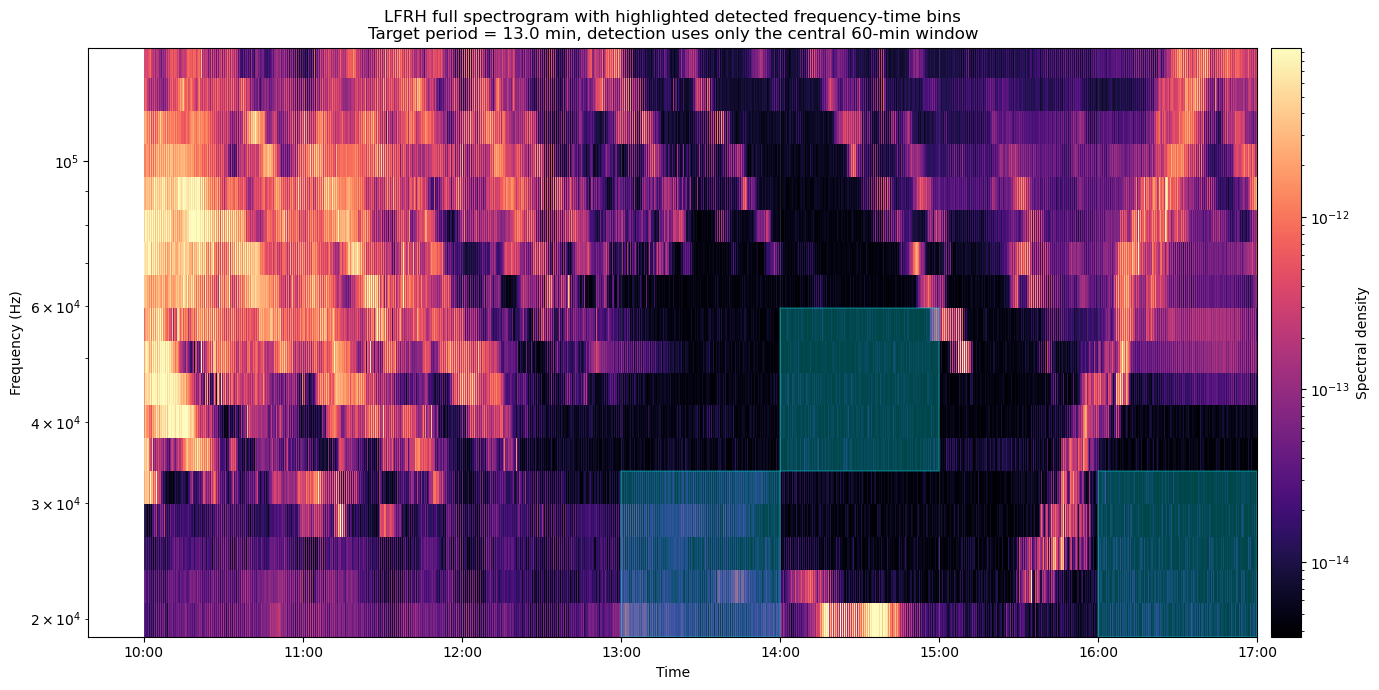

In [9]:
summary_df, rectangles_df = run_waves_cwt_target_period_highlight_downloaded(
    start_time="2017-07-11T10:00:00",
    end_time="2017-07-11T17:00:00",
    dataset="lfrh", # lhrl or lfrh
    rows_per_bin=5,
    pad_minutes=30,
    window_minutes=60,
    target_period_min=13.0,
    period_tolerance_frac=0.10,
    period_min_min=1.0,
    period_max_min=15.0,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",
    spike_threshold=1e4,
    detect_percentile=90,
    min_bins_detected=1,
    spec_cmap="magma",
    highlight_color="cyan",
    alpha_highlight=0.28,
    prefix="lfrh",
    save_fig=True,
    show_fig=True,
)

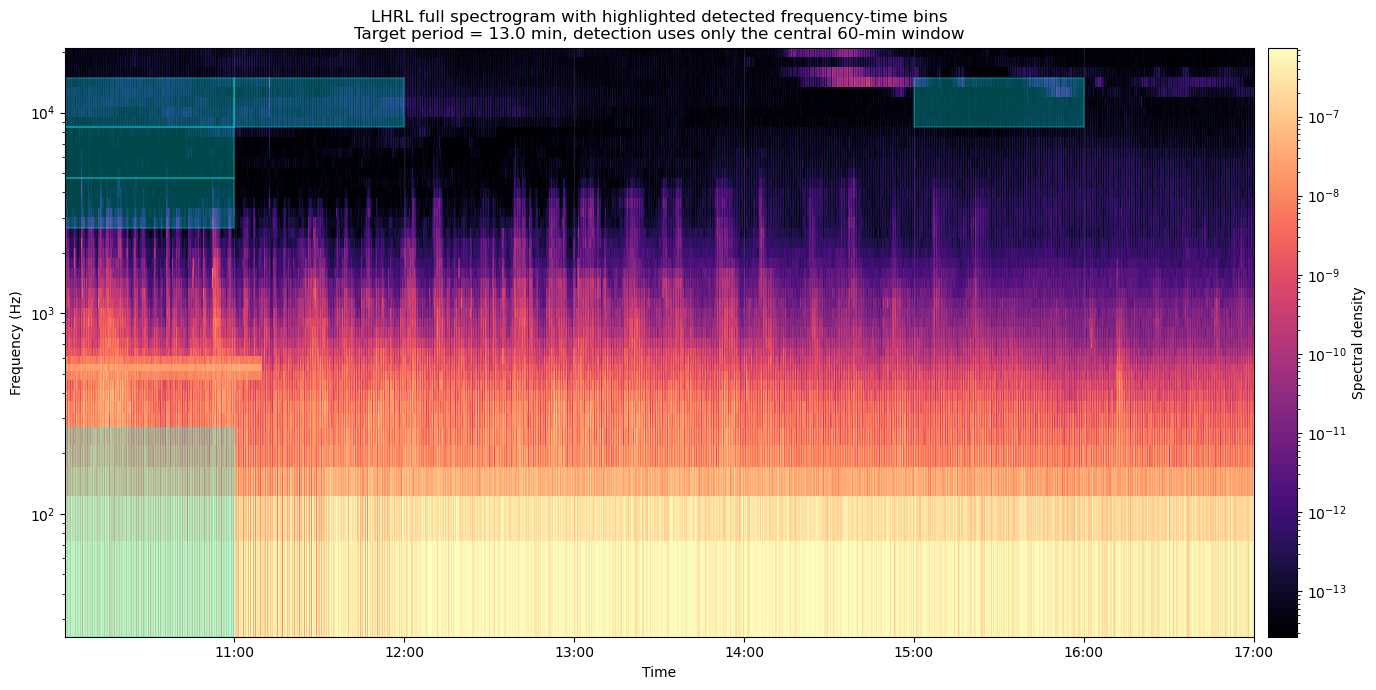

In [10]:
summary_df, rectangles_df = run_waves_cwt_target_period_highlight_downloaded(
    start_time="2017-07-11T10:00:00",
    end_time="2017-07-11T17:00:00",
    dataset="lhrl", # lhrl or lfrh
    rows_per_bin=5,
    pad_minutes=30,
    window_minutes=60,
    target_period_min=13.0,
    period_tolerance_frac=0.10,
    period_min_min=1.0,
    period_max_min=15.0,
    wavelet_name="cmor1.5-1.0",
    normalize_mode="fractional",
    spike_threshold=1e4,
    detect_percentile=90,
    min_bins_detected=1,
    spec_cmap="magma",
    highlight_color="cyan",
    alpha_highlight=0.28,
    prefix="lhrl",
    save_fig=True,
    show_fig=True,
)


=== P0801930801 ===
[XMM] P0801930801 seg 2: best P=9.07 min, quick FAP=0.584, counts=763
[NOTE] XMM period does not pass quick 95% threshold; still screening WAVES for context.

=== P0801930901 ===
[XMM] P0801930901 seg 1: best P=13.14 min, quick FAP=0.111, counts=756
[NOTE] XMM period does not pass quick 95% threshold; still screening WAVES for context.

=== P0801931901 ===
[XMM] P0801931901 seg 3: best P=4.28 min, quick FAP=0.09, counts=1104
[NOTE] XMM period does not pass quick 95% threshold; still screening WAVES for context.

=== P0882110501 ===
[XMM] P0882110501 seg 3: best P=12.50 min, quick FAP=0.00959, counts=738

=== P0882110601 ===
[XMM] P0882110601 seg 5: best P=12.50 min, quick FAP=0.000101, counts=1270

[SAVE] quick_driver_screen_outputs/quick_xmm_periods.csv
[SAVE] quick_driver_screen_outputs/quick_waves_driver_screen.csv

Top quick-look candidate driver links:
     obs_id  segment_index  xmm_best_period_min  xmm_fap_quick  freq_lo_hz  freq_hi_hz  waves_target_ratio  w

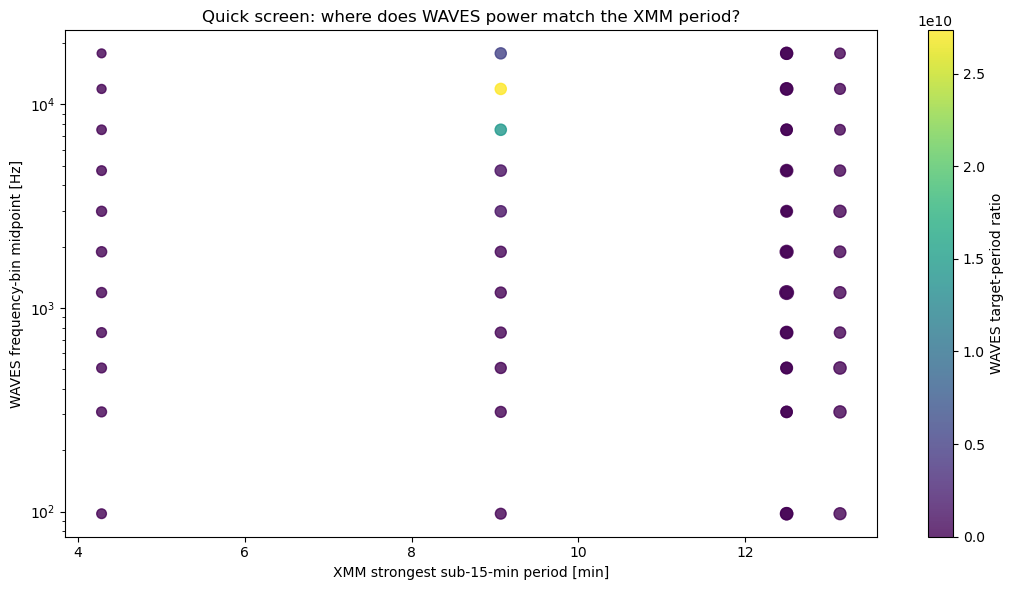

[SAVE] quick_driver_screen_outputs/quick_driver_map.png


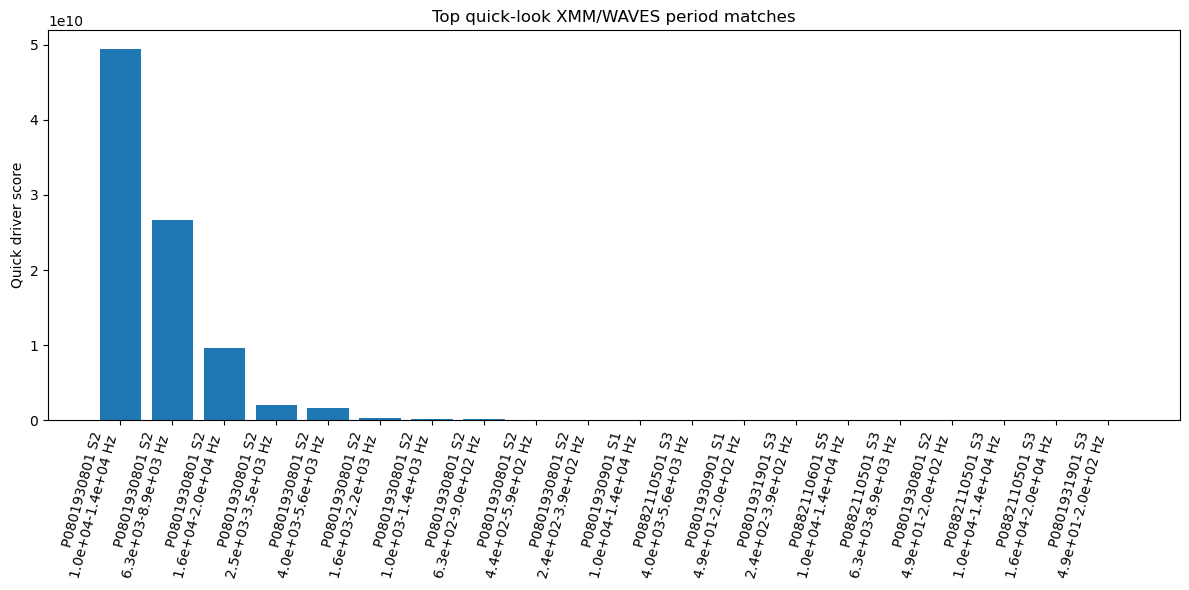

[SAVE] quick_driver_screen_outputs/top_quick_driver_candidates.png


In [5]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pywt

from astropy.table import Table
from astropy.time import Time
from astropy.timeseries import LombScargle
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u

from das2 import get_source


# =============================================================================
# USER SETTINGS
# =============================================================================

ident = ['P0801930801', 'P0801930901', 'P0801931901', 'P0882110501', 'P0882110601']

TARGET_SEGMENTS = {
    'P0801930801': 2,
    'P0801930901': 1,
    'P0801931901': 3,
    'P0882110501': 3,
    'P0882110601': 5,
}

data_dir = 'Data_Files/Fenn_Data/'

base_bin_size = 10
gap_threshold_s = 3600.0

xmm_period_min_min = 2.0
xmm_period_max_min = 15.0
xmm_nfreq = 5000

# This is a quick-look false alarm probability threshold.
# It is much faster than Monte Carlo, but less robust.
xmm_fap_threshold = 0.05

SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"

waves_dataset = "lhrl"      # "lhrl" or "lfrh"
rows_per_bin = 4

waves_pad_minutes = 30.0
wavelet_name = "cmor1.5-1.0"

waves_period_min_min = 1.0
waves_period_max_min = 15.0
cwt_n_periods = 100

period_tolerance_frac = 0.10
period_tolerance_min_floor = 0.5

normalize_mode = "fractional"
spike_threshold = 1e4

# Control-period comparison.
control_period_offsets_min = [-4, -3, -2, 2, 3, 4]

output_dir = "quick_driver_screen_outputs"
os.makedirs(output_dir, exist_ok=True)


# =============================================================================
# XMM LOADING
# =============================================================================

def load_combined_times(obs_id: str, data_dir: str):
    files = [f'{data_dir}EPIC_{obs_id}_{cam}_North_RFT.fit' for cam in ['PN', 'M1', 'M2']]
    list_dt, list_cxc = [], []

    for file in files:
        if not os.path.exists(file):
            print(f"[WARN] Missing file: {file}")
            continue

        data = Table.read(file, format="fits")

        t = Time(data['TIME'], format='cxcsec', scale='tt')
        with solar_system_ephemeris.set('de432s'):
            jup = get_body_barycentric('jupiter', t)
            xmm = get_body_barycentric('earth', t)

        distance_au = (jup - xmm).norm()
        light_time_s = (distance_au.to('m') / c).to('s').value

        corrected_t = t - light_time_s * u.s

        list_dt.append(corrected_t.datetime)
        list_cxc.append(corrected_t.cxcsec)

    if len(list_cxc) == 0:
        return np.array([]), np.array([])

    times_dt = np.hstack(list_dt)
    times_cxc = np.hstack(list_cxc)

    order = np.argsort(times_cxc)

    return times_dt[order], times_cxc[order]


def find_gaps(times_cxcsec, threshold=3600.0):
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    return indices


def split_into_segments(times_cxcsec, threshold=3600.0):
    if len(times_cxcsec) == 0:
        return []

    gap_indices = find_gaps(times_cxcsec, threshold=threshold)

    starts = np.r_[0, gap_indices + 1]
    ends = np.r_[gap_indices + 1, len(times_cxcsec)]

    return [times_cxcsec[i:j] for i, j in zip(starts, ends) if j > i]


def bin_photon_times(photon_times, bin_size):
    start = float(np.nanmin(photon_times))
    end = float(np.nanmax(photon_times))
    bins = np.arange(start, end + bin_size, bin_size)
    counts, edges = np.histogram(photon_times, bins=bins)
    centers = edges[:-1] + 0.5 * bin_size
    return centers, counts


def categorize_segment(counts, low_thresh=400, high_thresh=800):
    total = float(np.sum(counts))
    if total < low_thresh:
        return "low"
    elif total < high_thresh:
        return "medium"
    return "high"


def dynamic_bin_size(category, base_bin=10):
    if category == "low":
        return base_bin * 4
    elif category == "medium":
        return base_bin * 2
    return base_bin


def prepare_segment_bins(raw_segment, base_bin=10):
    _, counts0 = bin_photon_times(raw_segment, base_bin)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    centers, counts = bin_photon_times(raw_segment, seg_bin)

    return seg_bin, centers, counts, category


# =============================================================================
# QUICK XMM LS PERIOD SEARCH
# =============================================================================

def quick_xmm_period_search(obs_id, segment_index, photon_times_cxc):
    """
    Fast LS search for strongest 2-15 min XMM period.
    Uses analytic Lomb-Scargle FAP for speed.
    """
    seg_bin, t_cxc, counts, category = prepare_segment_bins(photon_times_cxc, base_bin_size)

    if len(t_cxc) < 5 or np.nanstd(counts) <= 0:
        return None

    t_s = t_cxc - t_cxc[0]
    y = counts - np.nanmean(counts)

    f_min = 1.0 / (xmm_period_max_min * 60.0)
    f_max = 1.0 / (xmm_period_min_min * 60.0)
    freqs = np.linspace(f_min, f_max, xmm_nfreq)

    ls = LombScargle(t_s, y)
    power = ls.power(freqs)

    best_idx = np.nanargmax(power)
    best_freq = freqs[best_idx]
    best_period_min = 1.0 / best_freq / 60.0
    best_power = power[best_idx]

    try:
        fap = ls.false_alarm_probability(best_power)
    except Exception:
        fap = np.nan

    duration_min = (np.nanmax(photon_times_cxc) - np.nanmin(photon_times_cxc)) / 60.0
    n_cycles = duration_min / best_period_min

    start_cxc = float(np.nanmin(photon_times_cxc))
    end_cxc = float(np.nanmax(photon_times_cxc))

    start_dt = Time(start_cxc, format="cxcsec", scale="tt").datetime
    end_dt = Time(end_cxc, format="cxcsec", scale="tt").datetime

    return {
        "obs_id": obs_id,
        "segment_index": segment_index,
        "xmm_start_cxc": start_cxc,
        "xmm_end_cxc": end_cxc,
        "xmm_start_datetime": start_dt,
        "xmm_end_datetime": end_dt,
        "duration_min": duration_min,
        "xmm_bin_size_s": seg_bin,
        "xmm_category": category,
        "total_counts": int(np.sum(counts)),
        "xmm_best_period_min": float(best_period_min),
        "xmm_best_power": float(best_power),
        "xmm_fap_quick": float(fap),
        "xmm_n_cycles": float(n_cycles),
        "xmm_passes_quick_95": bool(np.isfinite(fap) and fap <= xmm_fap_threshold),
    }


# =============================================================================
# WAVES LOADING AND CWT
# =============================================================================

def _ensure_dt64_ms(t):
    return np.array(t, dtype="datetime64[ms]")


def _parse_waves_dataset(d):
    f_arr = d["frequency"]["center"].array
    freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr

    t_arr = d["Time"]["center"].array
    times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr

    spec = d["spec_dens"]["center"].array

    times = _ensure_dt64_ms(times)
    freqs = np.asarray(freqs, dtype=float)
    spec = np.asarray(spec, dtype=float)

    return times, freqs, spec


def _download_waves_segment(start_time, end_time, dataset="lhrl"):
    source = get_source(SERVER_URL_WAVES)
    ds = source.get({"time": (start_time, end_time)})

    if len(ds) < 2:
        raise RuntimeError("Expected at least two datasets from DAS2.")

    if dataset.lower() == "lhrl":
        return _parse_waves_dataset(ds[0])
    elif dataset.lower() == "lfrh":
        return _parse_waves_dataset(ds[1])
    else:
        raise ValueError("dataset must be 'lhrl' or 'lfrh'")


def datetime_to_np64(dt):
    return np.datetime64(pd.Timestamp(dt).to_datetime64())


def normalize_series(y, mode="fractional"):
    y = np.asarray(y, dtype=float)

    if np.sum(np.isfinite(y)) < 3:
        return np.full_like(y, np.nan)

    mean = np.nanmean(y)
    std = np.nanstd(y)

    if mode == "fractional":
        if mean == 0 or not np.isfinite(mean):
            return np.full_like(y, np.nan)
        return (y - mean) / mean

    elif mode == "zscore":
        if std == 0 or not np.isfinite(std):
            return np.full_like(y, np.nan)
        return (y - mean) / std

    elif mode == "mean":
        if mean == 0 or not np.isfinite(mean):
            return np.full_like(y, np.nan)
        return y / mean

    elif mode == "none":
        return y.copy()

    else:
        raise ValueError("Unknown normalize_mode")


def interpolate_bad_values(y):
    y = np.asarray(y, dtype=float)
    x = np.arange(len(y))
    good = np.isfinite(y)

    if np.sum(good) < 3:
        return np.full_like(y, np.nan)

    return np.interp(x, x[good], y[good])


def remove_spikes(y, threshold=1e4):
    y = np.asarray(y, dtype=float)
    bad = ~np.isfinite(y) | (np.abs(y) > threshold)

    if np.sum(~bad) < 3:
        return np.full_like(y, np.nan), int(np.sum(bad))

    y2 = y.copy()
    x = np.arange(len(y))
    y2[bad] = np.interp(x[bad], x[~bad], y[~bad])

    return y2, int(np.sum(bad))


def make_frequency_bins(freqs, rows_per_bin=4):
    bins = []
    for i0 in range(0, len(freqs), rows_per_bin):
        i1 = min(i0 + rows_per_bin, len(freqs))
        bins.append((i0, i1, float(freqs[i0]), float(freqs[i1 - 1])))
    return bins


def summed_waves_series_for_freqbin(spec, i0, i1):
    return np.nansum(spec[:, i0:i1], axis=1)


def compute_cwt_power(times64, y):
    times64 = np.asarray(times64)
    y = np.asarray(y, dtype=float)

    if len(times64) < 5:
        return None, None

    t_sec = (times64 - times64[0]) / np.timedelta64(1, "s")
    dt = np.nanmedian(np.diff(t_sec))

    if not np.isfinite(dt) or dt <= 0:
        return None, None

    periods_min = np.geomspace(waves_period_min_min, waves_period_max_min, cwt_n_periods)
    periods_s = periods_min * 60.0

    wavelet = pywt.ContinuousWavelet(wavelet_name)
    cf = pywt.central_frequency(wavelet)

    scales = cf * periods_s / dt

    coeff, _ = pywt.cwt(y, scales, wavelet, sampling_period=dt)
    power = np.abs(coeff) ** 2

    return periods_min, power


def period_band_mask(periods_min, target_period_min):
    tol = max(target_period_min * period_tolerance_frac, period_tolerance_min_floor)
    lo = target_period_min - tol
    hi = target_period_min + tol
    return (periods_min >= lo) & (periods_min <= hi), lo, hi


def target_band_ratio(periods_min, power, times64, start64, end64, target_period_min):
    """
    Quick metric:
        mean target-band CWT power / median off-target CWT power
    """
    if periods_min is None or power is None:
        return np.nan, np.nan, np.nan, np.nan

    time_mask = (times64 >= start64) & (times64 <= end64)

    if np.sum(time_mask) < 5:
        return np.nan, np.nan, np.nan, np.nan

    band_mask, lo, hi = period_band_mask(periods_min, target_period_min)

    if np.sum(band_mask) == 0:
        return np.nan, lo, hi, np.nan

    target = power[np.ix_(band_mask, time_mask)]
    background = power[np.ix_(~band_mask, time_mask)]

    if target.size == 0 or background.size == 0:
        return np.nan, lo, hi, np.nan

    target_power = np.nanmean(target)
    background_power = np.nanmedian(background)

    if not np.isfinite(background_power) or background_power <= 0:
        ratio = np.nan
    else:
        ratio = target_power / background_power

    # Persistence diagnostic.
    bg_thr = np.nanpercentile(background, 90)
    target_vs_time = np.nanmean(target, axis=0)
    persistence = np.nanmean(target_vs_time > bg_thr)

    return float(ratio), float(lo), float(hi), float(persistence)


# =============================================================================
# DRIVER CLASSIFICATION
# =============================================================================

def classify_waves_response(freq_lo_hz, freq_hi_hz, ratio, persistence, control_percentile):
    """
    Quick interpretive labels. These are not physical proofs, just triage labels.
    """
    if not np.isfinite(ratio):
        return "no usable WAVES metric"

    if ratio < 1.5:
        return "weak/no matching WAVES enhancement"

    if control_percentile < 80:
        return "not period-specific; likely broadband/noisy variability"

    f_mid = np.sqrt(freq_lo_hz * freq_hi_hz)

    if f_mid < 1e3:
        band_label = "low-frequency WAVES response"
    elif f_mid < 2e4:
        band_label = "LHRL radio/plasma-wave response"
    elif f_mid < 2e5:
        band_label = "LFRH higher-frequency radio response"
    else:
        band_label = "high-frequency radio response"

    if persistence >= 0.5:
        persistence_label = "persistent"
    elif persistence >= 0.25:
        persistence_label = "intermittent"
    else:
        persistence_label = "burst-like"

    return f"{persistence_label} {band_label}"


# =============================================================================
# QUICK SCREENING PIPELINE
# =============================================================================

def quick_screen_one_target(obs_id, segment_index, photon_segment):
    xmm = quick_xmm_period_search(obs_id, segment_index, photon_segment)

    if xmm is None:
        print(f"[XMM] {obs_id} seg {segment_index}: no usable XMM period")
        return pd.DataFrame(), None

    target_period = xmm["xmm_best_period_min"]

    print(
        f"[XMM] {obs_id} seg {segment_index}: "
        f"best P={target_period:.2f} min, "
        f"quick FAP={xmm['xmm_fap_quick']:.3g}, "
        f"counts={xmm['total_counts']}"
    )

    if not xmm["xmm_passes_quick_95"]:
        print(f"[NOTE] XMM period does not pass quick 95% threshold; still screening WAVES for context.")

    central_start64 = datetime_to_np64(xmm["xmm_start_datetime"])
    central_end64 = datetime_to_np64(xmm["xmm_end_datetime"])

    pad = np.timedelta64(int(waves_pad_minutes * 60), "s")
    download_start64 = central_start64 - pad
    download_end64 = central_end64 + pad

    start_str = str(download_start64).replace(".000000", "")
    end_str = str(download_end64).replace(".000000", "")

    try:
        times, freqs, spec = _download_waves_segment(start_str, end_str, dataset=waves_dataset)
    except Exception as e:
        print(f"[WAVES] Download failed for {obs_id} seg {segment_index}: {e}")
        return pd.DataFrame(), xmm

    freq_bins = make_frequency_bins(freqs, rows_per_bin=rows_per_bin)

    rows = []

    for bin_idx, (i0, i1, f_lo, f_hi) in enumerate(freq_bins, start=1):
        y_raw = summed_waves_series_for_freqbin(spec, i0, i1)
        y = normalize_series(y_raw, normalize_mode)
        y = interpolate_bad_values(y)
        y, n_spikes = remove_spikes(y, spike_threshold)

        if np.sum(np.isfinite(y)) < 10 or np.nanstd(y) <= 0:
            continue

        periods_min, power = compute_cwt_power(times, y)

        if periods_min is None:
            continue

        ratio, p_lo, p_hi, persistence = target_band_ratio(
            periods_min,
            power,
            times,
            central_start64,
            central_end64,
            target_period,
        )

        control_ratios = []

        for off in control_period_offsets_min:
            cp = target_period + off
            if cp < waves_period_min_min or cp > waves_period_max_min:
                continue

            cr, _, _, _ = target_band_ratio(
                periods_min,
                power,
                times,
                central_start64,
                central_end64,
                cp,
            )

            if np.isfinite(cr):
                control_ratios.append(cr)

        control_ratios = np.asarray(control_ratios)

        if len(control_ratios) > 0 and np.isfinite(ratio):
            control_percentile = 100.0 * np.mean(control_ratios <= ratio)
            control_median = float(np.nanmedian(control_ratios))
        else:
            control_percentile = np.nan
            control_median = np.nan

        driver_label = classify_waves_response(
            f_lo,
            f_hi,
            ratio,
            persistence,
            control_percentile,
        )

        rows.append({
            **xmm,
            "waves_dataset": waves_dataset,
            "freq_bin_index": bin_idx,
            "freq_i0": i0,
            "freq_i1": i1,
            "freq_lo_hz": f_lo,
            "freq_hi_hz": f_hi,
            "freq_mid_hz": np.sqrt(f_lo * f_hi),
            "target_band_lo_min": p_lo,
            "target_band_hi_min": p_hi,
            "waves_target_ratio": ratio,
            "waves_persistence_fraction": persistence,
            "control_median_ratio": control_median,
            "control_percentile": control_percentile,
            "n_spikes_removed": n_spikes,
            "quick_driver_label": driver_label,
        })

    if len(rows) == 0:
        return pd.DataFrame(), xmm

    return pd.DataFrame(rows), xmm


def run_quick_driver_screen():
    all_results = []
    all_xmm = []

    for obs_id in ident:
        print(f"\n=== {obs_id} ===")

        _, times_cxc = load_combined_times(obs_id, data_dir)

        if len(times_cxc) == 0:
            print("[XMM] No events loaded")
            continue

        segments = split_into_segments(times_cxc, threshold=gap_threshold_s)

        if obs_id not in TARGET_SEGMENTS:
            print("[XMM] No target segment specified")
            continue

        seg_idx = TARGET_SEGMENTS[obs_id]

        if seg_idx < 1 or seg_idx > len(segments):
            print(f"[XMM] Segment {seg_idx} out of range; valid 1-{len(segments)}")
            continue

        df, xmm = quick_screen_one_target(obs_id, seg_idx, segments[seg_idx - 1])

        if xmm is not None:
            all_xmm.append(xmm)

        if len(df) > 0:
            all_results.append(df)

    xmm_df = pd.DataFrame(all_xmm)

    if len(all_results) == 0:
        print("[DONE] No WAVES quick-screen results.")
        return xmm_df, pd.DataFrame()

    results = pd.concat(all_results, ignore_index=True)

    xmm_path = os.path.join(output_dir, "quick_xmm_periods.csv")
    results_path = os.path.join(output_dir, "quick_waves_driver_screen.csv")

    xmm_df.to_csv(xmm_path, index=False)
    results.to_csv(results_path, index=False)

    print(f"\n[SAVE] {xmm_path}")
    print(f"[SAVE] {results_path}")

    return xmm_df, results


# =============================================================================
# PLOTS
# =============================================================================

def plot_quick_driver_map(results):
    if len(results) == 0:
        return

    df = results.copy()

    plt.figure(figsize=(11, 6))

    sc = plt.scatter(
        df["xmm_best_period_min"],
        df["freq_mid_hz"],
        c=df["waves_target_ratio"],
        s=40 + 120 * np.nan_to_num(df["waves_persistence_fraction"], nan=0.0),
        alpha=0.8,
    )

    plt.yscale("log")
    plt.colorbar(sc, label="WAVES target-period ratio")
    plt.xlabel("XMM strongest sub-15-min period [min]")
    plt.ylabel("WAVES frequency-bin midpoint [Hz]")
    plt.title("Quick screen: where does WAVES power match the XMM period?")
    plt.tight_layout()

    path = os.path.join(output_dir, "quick_driver_map.png")
    plt.savefig(path, dpi=200)
    plt.show()

    print(f"[SAVE] {path}")


def plot_top_frequency_response(results, top_n=20):
    if len(results) == 0:
        return

    df = results.copy()

    # Rank by high target ratio, period specificity, and persistence.
    df["score"] = (
        np.nan_to_num(df["waves_target_ratio"], nan=0.0)
        * (1.0 + np.nan_to_num(df["control_percentile"], nan=0.0) / 100.0)
        * (1.0 + np.nan_to_num(df["waves_persistence_fraction"], nan=0.0))
    )

    top = df.sort_values("score", ascending=False).head(top_n).copy()
    top["label"] = (
        top["obs_id"].astype(str)
        + " S" + top["segment_index"].astype(str)
        + "\n"
        + top["freq_lo_hz"].map(lambda x: f"{x:.1e}")
        + "-"
        + top["freq_hi_hz"].map(lambda x: f"{x:.1e}")
        + " Hz"
    )

    plt.figure(figsize=(12, 6))
    plt.bar(np.arange(len(top)), top["score"])
    plt.xticks(np.arange(len(top)), top["label"], rotation=75, ha="right")
    plt.ylabel("Quick driver score")
    plt.title("Top quick-look XMM/WAVES period matches")
    plt.tight_layout()

    path = os.path.join(output_dir, "top_quick_driver_candidates.png")
    plt.savefig(path, dpi=200)
    plt.show()

    print(f"[SAVE] {path}")


def print_quick_summary(results):
    if len(results) == 0:
        print("No quick-screen results to summarise.")
        return

    df = results.copy()

    df["score"] = (
        np.nan_to_num(df["waves_target_ratio"], nan=0.0)
        * (1.0 + np.nan_to_num(df["control_percentile"], nan=0.0) / 100.0)
        * (1.0 + np.nan_to_num(df["waves_persistence_fraction"], nan=0.0))
    )

    cols = [
        "obs_id",
        "segment_index",
        "xmm_best_period_min",
        "xmm_fap_quick",
        "freq_lo_hz",
        "freq_hi_hz",
        "waves_target_ratio",
        "waves_persistence_fraction",
        "control_percentile",
        "quick_driver_label",
        "score",
    ]

    print("\nTop quick-look candidate driver links:")
    print(
        df[cols]
        .sort_values("score", ascending=False)
        .head(25)
        .to_string(index=False)
    )

    print("\nInterpretation guide:")
    print("  - waves_target_ratio > 1 means enhanced WAVES CWT power near the XMM period.")
    print("  - control_percentile near 100 means the XMM period is stronger than nearby control periods.")
    print("  - high persistence means the signal lasts through more of the XMM segment.")
    print("  - This is a screening tool, not a final significance test.")


# =============================================================================
# RUN
# =============================================================================

if __name__ == "__main__":
    xmm_df, results = run_quick_driver_screen()

    print_quick_summary(results)

    if len(results) > 0:
        plot_quick_driver_map(results)
        plot_top_frequency_response(results, top_n=20)